# Multivariate regression of charging point density

This notebook answers the main research question: which characteristics explain the most variation in public charging points per 1,000 households, when all are considered together (report section 7)?

**Input:** `data/processed/alle_variabelen_per_gemeente.csv`, created by notebook 6.

**Approach**
1. Select one variable from each pair of strongly correlated variables (|r| ≥ 0.66 in notebook 6), to avoid multicollinearity.
2. Estimate an ordinary least squares (OLS) regression on standardised variables, so that the coefficients (β) can be compared directly: β is the change in charging point density, in standard deviations, when a variable increases by one standard deviation and the others stay the same.
3. Use heteroskedasticity-robust standard errors (HC3), because the spread of the residuals may differ between small and large municipalities.
4. Check multicollinearity with variance inflation factors (VIF) and inspect the residuals.
5. Test two alternative specifications as robustness checks.

**Outputs:** `data/processed/regressie_resultaten.csv`, `figures/figuur_regressie_coefficienten.png`, `figures/figuur_regressie_residuen.png`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROCESSED = "../data/processed/"
FIGURES = "../figures/"


## 1. Load the data and prepare the variables

Population density is strongly right-skewed: a few cities are far denser than the rest. Its natural logarithm is used, which in notebook 6 gave a stronger and more linear relation with charging point density (r = 0.48 against 0.41).

In [2]:
df = pd.read_csv(PROCESSED + "alle_variabelen_per_gemeente.csv")
df["log_bevolkingsdichtheid"] = np.log(df["bevolkingsdichtheid"])

TARGET = "laadpunten_per_1000_huishoudens"
LABELS = {
    "med_gestandaardiseerd_inkomen_keur": "Median standardised income",
    "hoogopgeleid_pct": "Highly educated (%)",
    "linkse_stemmen_pct": "Left-wing vote share (%)",
    "ouderen_65plus_pct": "Residents 65+ (%)",
    "log_bevolkingsdichtheid": "Population density (log)",
    "meergezinswoning_pct": "Apartments (% of dwellings)",
}
print("Municipalities:", len(df))

Municipalities: 342


## 2. Choice of variables

Notebook 6 showed four pairs of strongly correlated variables. From each pair one variable is kept:

| Pair (r) | Kept | Reason |
| --- | --- | --- |
| Under 25 and 65+ (−0.82) | 65+ | Slightly stronger link with charging point density |
| Mean and median income (0.66) | Median | Not distorted by a few very rich municipalities |
| Population density and apartments (0.79) | Density (log) | Strongest single factor; apartments used in a robustness check |
| Left-wing vote share and education (0.78) | Education in the main model | Vote share is tested in model 2 instead of education |

Three models are estimated:
- **Model 1 (main):** income, education, 65+ and population density.
- **Model 2:** left-wing vote share instead of education, to test political preference.
- **Model 3:** share of apartments instead of population density, as a second indicator of need.

In [3]:
MODELS = {
    "Model 1 (main)": ["med_gestandaardiseerd_inkomen_keur", "hoogopgeleid_pct",
                       "ouderen_65plus_pct", "log_bevolkingsdichtheid"],
    "Model 2 (vote share)": ["med_gestandaardiseerd_inkomen_keur", "linkse_stemmen_pct",
                             "ouderen_65plus_pct", "log_bevolkingsdichtheid"],
    "Model 3 (apartments)": ["med_gestandaardiseerd_inkomen_keur", "hoogopgeleid_pct",
                             "ouderen_65plus_pct", "meergezinswoning_pct"],
}


def fit_standardised(data, predictors):
    """Fit OLS on z-scores with HC3 robust standard errors; return model, data used and VIFs."""
    used = data[[TARGET] + predictors].dropna()
    z = (used - used.mean()) / used.std()
    formula = TARGET + " ~ " + " + ".join(predictors)
    model = smf.ols(formula, data=z).fit(cov_type="HC3")
    X = sm.add_constant(z[predictors])
    vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                    index=predictors)
    return model, used, vif


results = {name: fit_standardised(df, preds) for name, preds in MODELS.items()}

## 3. Results of the main model

The table shows the standardised coefficient (β), its 95% confidence interval, the p-value and the VIF per variable. A VIF below 5 means multicollinearity is not a problem.

In [4]:
model, used, vif = results["Model 1 (main)"]
ci = model.conf_int()
main = pd.DataFrame({
    "β (standardised)": model.params,
    "95% CI low": ci[0],
    "95% CI high": ci[1],
    "p-value": model.pvalues,
}).drop(index="Intercept")
main["VIF"] = vif
main.index = [LABELS[i] for i in main.index]

print(f"N = {int(model.nobs)},  R² = {model.rsquared:.3f},  adjusted R² = {model.rsquared_adj:.3f}")
main.round(3)

N = 339,  R² = 0.362,  adjusted R² = 0.354


,β (standardised),95% CI low,95% CI high,p-value,VIF
Median standardised income,0.372,0.265,0.479,0.000,1.513
Highly educated (%),-0.085,-0.211,0.042,0.190,1.840
Residents 65+ (%),-0.129,-0.232,-0.025,0.015,1.327
Population density (log),0.451,0.344,0.558,0.000,1.678


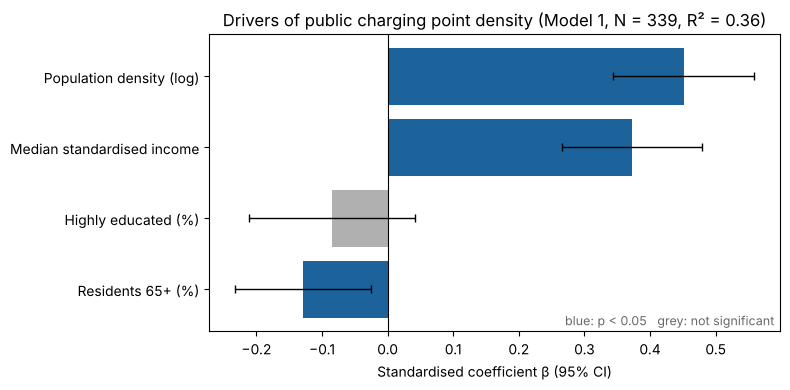

In [5]:
# Figure: standardised coefficients with 95% confidence intervals
plot = main.sort_values("β (standardised)")
colors = ["#1d639b" if p < 0.05 else "#b0b0b0" for p in plot["p-value"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(plot.index, plot["β (standardised)"], color=colors)
ax.errorbar(plot["β (standardised)"], plot.index,
            xerr=[plot["β (standardised)"] - plot["95% CI low"], plot["95% CI high"] - plot["β (standardised)"]],
            fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardised coefficient β (95% CI)")
ax.set_title(f"Drivers of public charging point density (Model 1, N = {int(model.nobs)}, R² = {model.rsquared:.2f})")
ax.text(0.99, 0.02, "blue: p < 0.05   grey: not significant", transform=ax.transAxes,
        ha="right", fontsize=9, color="dimgray")
plt.tight_layout()
plt.savefig(FIGURES + "figuur_regressie_coefficienten.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Comparison of the three models

If a coefficient keeps its sign and significance across the models, the result does not depend on the exact choice of variables.

In [6]:
rows = []
for name, (m, u, v) in results.items():
    for var in m.params.index.drop("Intercept"):
        rows.append({"Model": name, "Variable": LABELS[var], "β": m.params[var],
                     "p-value": m.pvalues[var], "VIF": v[var]})
    rows.append({"Model": name, "Variable": "R² (adjusted)", "β": m.rsquared_adj,
                 "p-value": np.nan, "VIF": np.nan})
    rows.append({"Model": name, "Variable": "N", "β": m.nobs, "p-value": np.nan, "VIF": np.nan})

comparison = pd.DataFrame(rows)
comparison.to_csv(PROCESSED + "regressie_resultaten.csv", index=False)

ORDER = [LABELS[v] for v in LABELS] + ["R² (adjusted)", "N"]
wide = comparison.pivot_table(index="Variable", columns="Model", values="β", sort=False).reindex(ORDER)
wide.round(3)

Model,Model 1 (main),Model 2 (vote share),Model 3 (apartments)
Variable,,,
Median standardised income,0.372,0.329,0.578
Highly educated (%),-0.085,NaN,-0.243
Left-wing vote share (%),NaN,-0.037,NaN
Residents 65+ (%),-0.129,-0.136,-0.132
Population density (log),0.451,0.433,NaN
Apartments (% of dwellings),NaN,NaN,0.525
R² (adjusted),0.354,0.351,0.342
N,339.000,339.000,339.000


In [7]:
# Significance per model (p-values)
comparison.pivot_table(index="Variable", columns="Model", values="p-value", sort=False).reindex(ORDER[:-2]).round(4)

Model,Model 1 (main),Model 2 (vote share),Model 3 (apartments)
Variable,,,
Median standardised income,0.0000,0.0000,0.0000
Highly educated (%),0.1900,NaN,0.0019
Left-wing vote share (%),NaN,0.5239,NaN
Residents 65+ (%),0.0152,0.0103,0.0156
Population density (log),0.0000,0.0000,NaN
Apartments (% of dwellings),NaN,NaN,0.0000


## 5. Residual diagnostics

OLS assumes that the residuals have no pattern against the fitted values and are roughly normally distributed. The left plot checks the first assumption, the right plot (Q-Q plot) the second. The municipalities with the largest residuals are listed below: these have far more or far fewer charging points than the model predicts.

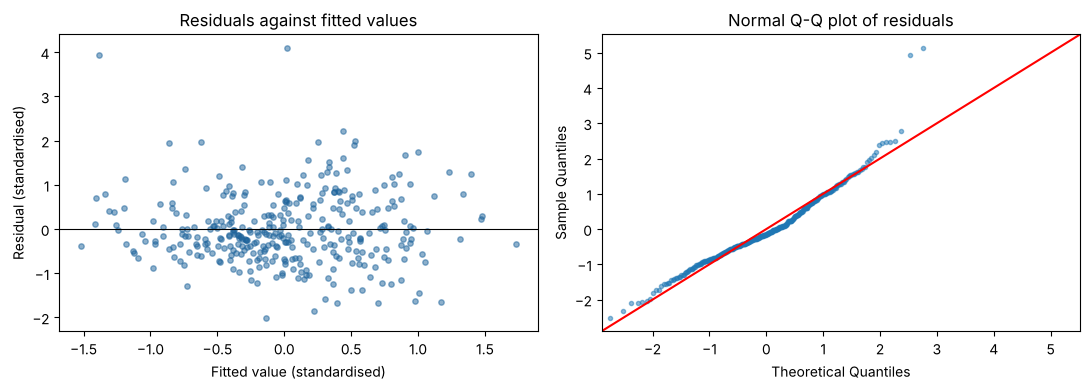

In [8]:
resid = model.resid
fitted = model.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fitted, resid, alpha=0.5, s=15, color="#1d639b")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Fitted value (standardised)")
axes[0].set_ylabel("Residual (standardised)")
axes[0].set_title("Residuals against fitted values")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=3, alpha=0.5)
axes[1].set_title("Normal Q-Q plot of residuals")
plt.tight_layout()
plt.savefig(FIGURES + "figuur_regressie_residuen.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
# Municipalities with the largest positive and negative residuals
names = df.loc[used.index, "gemeente"]
largest = pd.DataFrame({"Municipality": names, "Residual (SD)": resid,
                        "Charging points per 1,000 households": used[TARGET]})
pd.concat([largest.nlargest(5, "Residual (SD)"), largest.nsmallest(5, "Residual (SD)")]).round(2)

,Municipality,Residual (SD),"Charging points per 1,000 households"
169,Loon op Zand,4.10,42.88
255,Sluis,3.93,32.23
57,Culemborg,2.23,33.05
182,Midden-Delfland,1.98,32.03
289,Veere,1.98,24.23
231,Renkum,-2.00,0.54
322,Wijk bij Duurstede,-1.85,4.04
335,Zoeterwoude,-1.68,6.34
51,Bunschoten,-1.68,8.41
110,Haarlem,-1.64,11.85
